In [1]:
# Inicjalizacja podstawowych zmiennych planszy (Zadanie 2)
MAPA = [
    "....................",
    ".....###....#####...",
    "..#####........##...",
    "...#....#...#..###..",
    "...#...######....#..",
    "...#####.........#..",
    ".......#....#...#...",
    "...........##......."
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]
rows = len(grid)
cols = len(grid[0])

start = (1, 1)
goal = (6, 18)

print("Zmienne zostały pomyślnie zdefiniowane:")
print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Zmienne zostały pomyślnie zdefiniowane:
Rozmiar planszy: 8 x 20
Start: (1, 1)
Cel: (6, 18)


# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [2]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math
"""
# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)
"""
#ZADANIE 2
#Zawartość bez apostrofów to zmienione zadanie
MAPA = [
    "....................",
    ".....###....#####...",
    "..#####........##...",
    "...#....#...#..###..",
    "...#...######....#..",
    "...#####.........#..",
    ".......#....#...#...",
    "...........##......."
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]
rows = len(grid)
cols = len(grid[0])

start = (1, 1)
goal = (6, 18)

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 8 x 20
Start: (1, 1)
Cel: (6, 18)



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [3]:
"""
def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))
"""
#ZADANIE 1
#Zawartość bez apostrofów to zmienione zadanie

def get_neighbors_diagonal(state):
    r, c = state

    # 8 kierunków
    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
        (-1, -1), # lewy-górny
        (-1, 1),  # prawy-górny
        (1, -1),  # lewy-dolny
        (1, 1),   # prawy-dolny
    ]

    neighbors = []
    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors
    '''
def get_neighbors(state):
    r, c = state

    # Zmieniona kolejność: prawo, dół, lewo, góra
    moves = [
        (0, -1),  # lewo
        (1, 0),   # dół
        (-1, 0),  # góra
        (0, 1),   # prawo
    ]

    neighbors = []
    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        # Zmienne rows, cols oraz grid pochodzą z globalnego kontekstu notatnika
        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors
'''
    print("Sąsiedzi startu:", get_neighbors(start))

In [4]:
# Nadpisanie domyślnej funkcji sąsiedztwa na ruchy po przekątnej
get_neighbors = get_neighbors_diagonal
print("Sąsiedzi startu po przekątnej:", get_neighbors(start))

Sąsiedzi startu po przekątnej: [(0, 1), (2, 1), (1, 0), (1, 2), (0, 0), (0, 2), (2, 0)]



## 2. Wizualizacja problemu


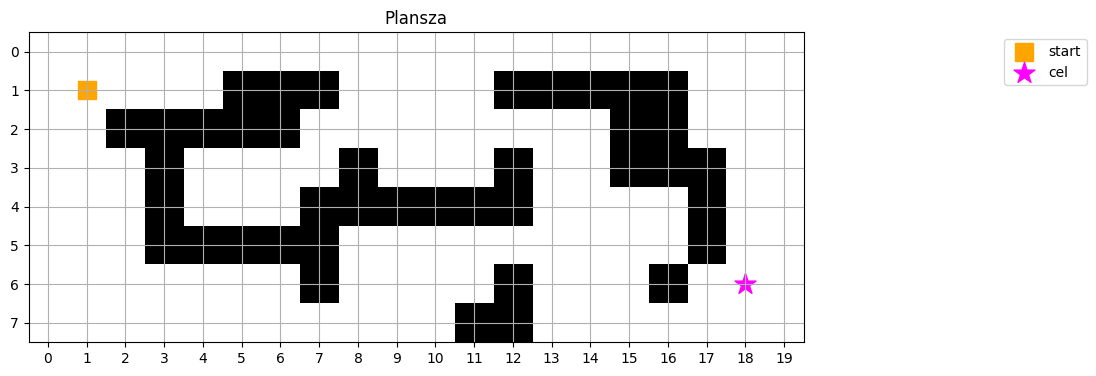

In [5]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


In [6]:
# Ponowne uruchomienie BFS z ruchami diagonalnymi
bfs_path, bfs_visited = bfs(start, goal)

print("BFS (skosy) - długość ścieżki:", len(bfs_path) - 1)
print("BFS (skosy) - odwiedzone stany:", len(bfs_visited))
print("BFS (skosy) - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS (skosy)")

NameError: name 'bfs' is not defined


### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?
2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

In [ ]:
# Ponowne uruchomienie DFS z ruchami diagonalnymi
dfs_path, dfs_visited = dfs(start, goal)

print("DFS (skosy) - długość ścieżki:", len(dfs_path) - 1)
print("DFS (skosy) - odwiedzone stany:", len(dfs_visited))
print("DFS (skosy) - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS (skosy)")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [ ]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )


### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


In [ ]:
# Ponowne uruchomienie Greedy z ruchami diagonalnymi
greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy (skosy) - długość ścieżki:", len(greedy_path) - 1)
print("Greedy (skosy) - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search (skosy)")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


In [ ]:
# Ponowne uruchomienie A* z ruchami diagonalnymi
astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* (skosy) - koszt:", astar_cost)
print("A* (skosy) - odwiedzone stany:", len(astar_visited))
print("A* (skosy) - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan (skosy)")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [ ]:

results = [
    ("BFS", len(bfs_path) - 1, len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, len(greedy_visited)),
    ("A*", len(astar_path) - 1, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Długość ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 50)

for name, path_len, visited_count in results:
    print(f"{name:<12} {path_len:<18} {visited_count}")



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [ ]:

astar_euclidean_path, astar_euclidean_visited, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


In [ ]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))



# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


In [ ]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)



# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

Odpowiedź: Zmiana kolejności sprawi, że DFS pokaże nam inną trasę i odwiedzi inną liczbę stanów. DFS idzie w pierwszą gałąź, którą widzi, więc zmiana "priorytetów" spowoduje wejście w zupełnie inny obszar drzewa poszukiwań.

---

## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.

Odpowiedź: zadanie wykonane powyżej
---

## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def chebyshev(a, b):
    # max(|x1 - x2|, |y1 - y2|)
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))

# Użycie w A*:
# astar_path, astar_visited, cost = astar(start, goal, heuristic=chebyshev)
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.


Odpowiedź: Wrzucamy odległość Czebyszewa (zwraca największą różnicę między X lub Y). Na siatce bez skosów będzie ona za bardzo zaniżać odległość, przez co A* sprawdzi więcej pól niż na Manhattanie, ale algorytm nadal znajdzie najlepszą trasę, bo heurystyka nie łamie zasady dopuszczalności.

---

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?
2. Jaką heurystykę zastosować?
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

ODPOWIEDŹ: Manhattan odpada – przeszacowuje koszt (widzi skos jako 2 ruchy zamiast 1), przez co A* przestaje być optymalny. Jeśli skos kosztuje 1, bierzemy Czebyszewa; jeśli skos kosztuje pierwiastek z 2 to musimy użyć Euklidesa albo specjalnej heurystyki Octile.  

---

## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

ODPOWIEDŹ:
Nie,
Algorytm BFS traktuje wszystkie przejścia jako równe i zawsze znajduje drogę o najmniejszej liczbie kroków. Jeśli krótsza w krokach ścieżka wiedzie przez bardzo drogie bagno, BFS ją wybierze, ignorując fakt, że omijająca bagno obwodnica o większej liczbie kroków jest sumarycznie tańsza. Przy zmiennych kosztach terenu należy używać algorytmu A* (lub Dijkstry, czyli A* z h(n)=0).

---

## Zadanie 6 — pytanie koncepcyjne

Wyjaśnij własnymi słowami różnicę między:

$$
g(n)
$$

a

$$
h(n)
$$

w algorytmie A*.

ODPOWIEDŹ:

g(n) reprezentuje rzeczywisty, skumulowany koszt dotarcia od punktu startowego do bieżąco analizowanego stanu. Stanowi historię dotychczasowej, znanej wędrówki.

h(n) to funkcja heurystyczna, czyli szacunkowy (prognozowany) dystans, jaki pozostał z bieżącego stanu do punktu docelowego. Służy ona jedynie ukierunkowaniu wyszukiwania algorytmu na podstawie zewnętrznej logiki geometrycznej.

# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [ ]:
# Miejsce na rozwiązanie zadania 8-puzzle.

start_puzzle = (
    0, 2, 4,
    3, 6, 5,
    7, 1, 8
)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

# TODO:
# 1. napisz funkcję generującą sąsiadów,
# 2. napisz heurystykę Manhattan,
# 3. wykorzystaj A*.

# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne

1. Co jest stanem w problemie wyszukiwania drogi?
2. Czym różni się BFS od DFS?
3. Dlaczego BFS może potrzebować dużo pamięci?
4. Co oznacza $g(n)$?
5. Co oznacza $h(n)$?
6. Co oznacza $f(n)$?
7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
8. Co oznacza, że heurystyka jest dopuszczalna?
9. Co się stanie w A*, gdy $h(n)=0$?
10. Czy A* zawsze jest szybszy od BFS?
